# Benchmark Level 1: medium tak hingga, 1 grup (MCMR vs OpenMC)

Data penampang lintang dan parameter simulasi didefinisikan **sekali** di sel konfigurasi, lalu dipakai oleh kedua kode. Semua sisi reflektif, sehingga hasil tidak bergantung pada dimensi (2D di MCMR, 3D di OpenMC).

Referensi analitik: k∞ = ν·Σf / Σa(total), dengan Σa(total) = Σt − Σs.

**Prasyarat:** `mcmr` terpasang (`pip install .` dari repo) dan OpenMC 0.16 (conda-forge) di environment yang sama.

**Keluaran:** dua file CSV di folder `OUTPUT_DIR`:
- `k_mcmr_per_generation.csv`: k setiap generasi untuk setiap run MCMR.
- `k_openmc_per_generation.csv`: k setiap generasi untuk setiap run OpenMC (estimator collision, tracklength, dan absorption).

**Catatan konvensi:** di MCMR "sigma_a" hanya tangkapan; di OpenMC absorpsi sudah termasuk fisi, sehingga OpenMC diberi Σt − Σs.

## 1. Konfigurasi

In [1]:
import os

# --- Data penampang lintang makroskopik (1 grup, satuan 1/cm) ---
sigma_t = 1.0     # total
sigma_s = 0.5     # hamburan
sigma_f = 0.24    # fisi
nu      = 2.5     # neutron per fisi

# --- Parameter simulasi ---
N      = 20000    # partikel per generasi
n_gen  = 220      # jumlah generasi per run
n_skip = 20       # generasi awal yang dibuang (tidak dipakai di statistik)
N_run  = 5        # jumlah run independen per kode
L      = 10.0     # sisi kotak (cm)

OUTPUT_DIR = "output_level1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

k_analitik = nu * sigma_f / (sigma_t - sigma_s)
print("k-inf analitik =", k_analitik)

k-inf analitik = 1.2


## 2. MCMR

### 2.1 Geometri MCMR

/home/azma/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


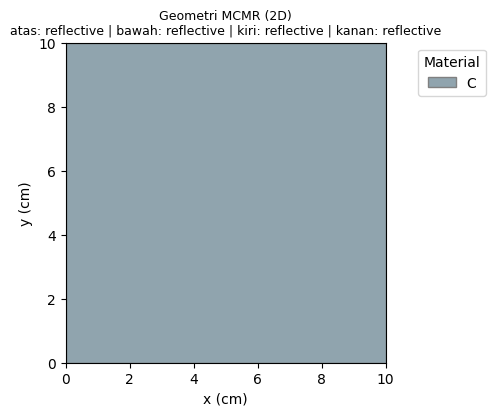

In [2]:
import io, sys, contextlib, csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
import mcmr

MATERIAL = "C"   # MCMR hanya mengenal Be, C, Fe, Pb (hanya label; datanya dari library di bawah)
lib = mcmr.MaterialLibrary().add_material(MATERIAL, [sigma_t], [sigma_s], [sigma_f], [nu])

world = mcmr.World(x_world=L, y_world=L, x_grid=[], y_grid=[],
                   material_matrix=[[MATERIAL]], sources=[[1]],
                   bc_top="reflective", bc_bot="reflective",
                   bc_left="reflective", bc_right="reflective")

def plot_mcmr_geometry(w, ax):
    colors = {"Fe": "#cfd8dc", "Pb": "#bcaaa4", "C": "#90a4ae", "Be": "#c8e6c9"}
    xe = [0.0] + list(w.x_grid) + [w.x_world]
    ye = [0.0] + list(w.y_grid) + [w.y_world]
    ny = len(ye) - 1
    used = {}
    for row in range(ny):                       # row 0 = baris paling atas
        for col in range(len(xe) - 1):
            m = w.material_matrix[row][col]; iy = ny - 1 - row
            ax.add_patch(Rectangle((xe[col], ye[iy]), xe[col+1]-xe[col], ye[iy+1]-ye[iy],
                                   facecolor=colors.get(m, "#dddddd"), edgecolor="gray"))
            used[m] = colors.get(m, "#dddddd")
    for c in w.circles:
        ax.add_patch(Circle((c["cx"], c["cy"]), c["r"], facecolor=colors.get(c["material"], "#dddddd"),
                            edgecolor="black"))
        used[c["material"]] = colors.get(c["material"], "#dddddd")
    ax.set_xlim(0, w.x_world); ax.set_ylim(0, w.y_world); ax.set_aspect("equal")
    ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)")
    ax.set_title(f"Geometri MCMR (2D)\natas: {w.bc_top} | bawah: {w.bc_bot} | kiri: {w.bc_left} | kanan: {w.bc_right}", fontsize=9)
    ax.legend(handles=[Rectangle((0,0),1,1,facecolor=c,edgecolor="gray",label=m) for m,c in used.items()],
              loc="upper left", bbox_to_anchor=(1.08, 1.0), title="Material")

fig, ax = plt.subplots(figsize=(5, 5))
plot_mcmr_geometry(world, ax); plt.tight_layout(); plt.show()

### 2.2 Jalankan MCMR

In [3]:
class _MCMRProgress:
    """Meneruskan baris progress MCMR ("Gen .. | Particle: [..]") dengan awalan 'Run i/N_run'.
    Banner awal dan ringkasan akhir (yang memuat k) tidak ditampilkan."""
    def __init__(self, real, run_idx, n_run):
        self.real, self.run_idx, self.n_run = real, run_idx, n_run
    def write(self, s):
        if s.startswith("\rGen"):
            return self.real.write(f"\rRun {self.run_idx}/{self.n_run} | " + s[1:])
        if "died" in s:                         # peringatan penting tetap diteruskan
            return self.real.write(s)
        return len(s)
    def flush(self): self.real.flush()
    def __getattr__(self, name): return getattr(self.real, name)

mcmr_rows = []     # (run, generation, k)
for run in range(1, N_run + 1):
    real = sys.stdout
    sys.stdout = _MCMRProgress(real, run, N_run)
    try:
        sim = world.run(N=N, mode="group", group_materials=lib, n_gen=n_gen, max_save=0, resolution=1)
    finally:
        sys.stdout = real
    k_gen = np.array(sim.get_tally().k_estimate)
    mcmr_rows += [(run, g + 1, float(k)) for g, k in enumerate(k_gen)]
print(f"\nMCMR selesai: {N_run} run x {n_gen} generasi")

mcmr_csv = os.path.join(OUTPUT_DIR, "k_mcmr_per_generation.csv")
with open(mcmr_csv, "w", newline="") as f:
    wr = csv.writer(f); wr.writerow(["run", "generation", "k"]); wr.writerows(mcmr_rows)
print("Disimpan:", mcmr_csv, f"({len(mcmr_rows)} baris)")

Run 5/5 | Gen 220/220 | Particle: [20000/20000] (100%) | Fission bank: 19698      
MCMR selesai: 5 run x 220 generasi
Disimpan: output_level1/k_mcmr_per_generation.csv (1100 baris)


## 3. OpenMC

OpenMC dijalankan dengan `inactive = 0` dan statepoint ditulis **setiap batch**, sehingga nilai collision, tracklength, dan absorption per generasi bisa diperoleh dari selisih global tally kumulatif. Pembuangan generasi awal (`n_skip`) dilakukan saat analisis, sama seperti pada MCMR.

In [4]:
import shutil, subprocess, tempfile, re
import openmc, openmc.mgxs

sigma_a = sigma_t - sigma_s    # absorpsi OpenMC = tangkapan + fisi

def build_openmc_model(wd, seed=1):
    """Tulis semua input OpenMC (multigrup, 1 grup) ke folder wd."""
    groups = openmc.mgxs.EnergyGroups(np.array([0.0, 20.0e6]))
    x = openmc.XSdata('mat', groups); x.order = 0
    x.set_total([sigma_t]); x.set_absorption([sigma_a])
    x.set_scatter_matrix(np.array([[[sigma_s]]]))
    x.set_fission([sigma_f]); x.set_nu_fission([nu * sigma_f]); x.set_chi([1.0])
    mg = openmc.MGXSLibrary(groups); mg.add_xsdata(x)
    mgxs_path = os.path.join(wd, 'mgxs.h5'); mg.export_to_hdf5(mgxs_path)

    mat = openmc.Material(name='mat'); mat.set_density('macro', 1.0); mat.add_macroscopic('mat')
    mats = openmc.Materials([mat]); mats.cross_sections = mgxs_path

    px0, px1 = openmc.XPlane(0, boundary_type='reflective'), openmc.XPlane(L, boundary_type='reflective')
    py0, py1 = openmc.YPlane(0, boundary_type='reflective'), openmc.YPlane(L, boundary_type='reflective')
    pz0, pz1 = openmc.ZPlane(0, boundary_type='reflective'), openmc.ZPlane(L, boundary_type='reflective')
    cell = openmc.Cell(name='kotak', fill=mat, region=+px0 & -px1 & +py0 & -py1 & +pz0 & -pz1)
    geom = openmc.Geometry([cell])

    s = openmc.Settings()
    s.energy_mode = 'multi-group'; s.run_mode = 'eigenvalue'
    s.particles = N; s.batches = n_gen; s.inactive = 0; s.seed = seed
    s.source = openmc.IndependentSource(space=openmc.stats.Box((0, 0, 0), (L, L, L)),
                                        energy=openmc.stats.Discrete([1.0e6], [1.0]))
    s.statepoint = {'batches': list(range(1, n_gen + 1))}
    s.sourcepoint = {'write': False}
    s.output = {'tallies': False}

    mats.export_to_xml(os.path.join(wd, 'materials.xml'))
    geom.export_to_xml(os.path.join(wd, 'geometry.xml'))
    s.export_to_xml(os.path.join(wd, 'settings.xml'))
    return openmc.Model(geometry=geom, materials=mats, settings=s)

### 3.1 Geometri OpenMC

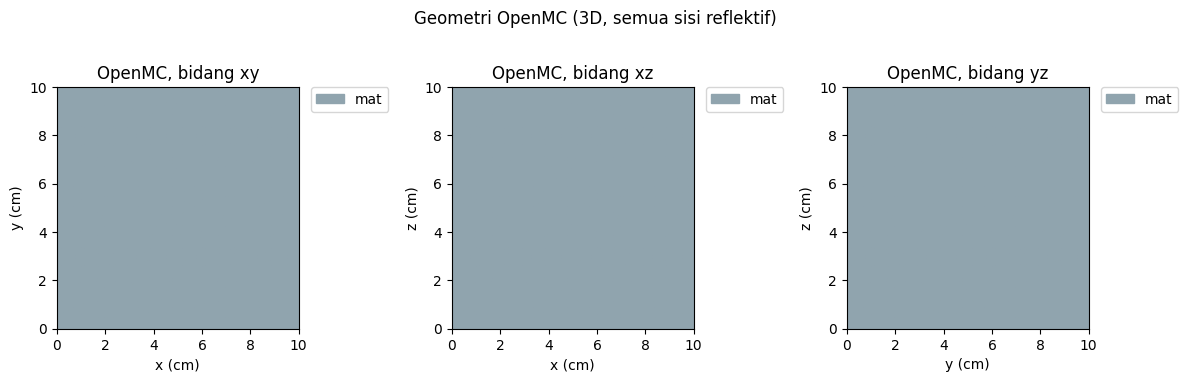

In [5]:
wd_plot = tempfile.mkdtemp(prefix="omc_geom_")
model_plot = build_openmc_model(wd_plot)
openmc.config['mg_cross_sections'] = os.path.join(wd_plot, 'mgxs.h5')   # dibutuhkan untuk plot geometri mode multigrup

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, basis, (xl, yl) in zip(axes, ("xy", "xz", "yz"), (("x", "y"), ("x", "z"), ("y", "z"))):
    model_plot.geometry.root_universe.plot(origin=(L/2, L/2, L/2), width=(L, L), basis=basis,
                                           color_by='material', axes=ax,
                                           colors={model_plot.materials[0]: (144, 164, 174)}, legend=True)
    ax.set_title(f"OpenMC, bidang {basis}"); ax.set_xlabel(f"{xl} (cm)"); ax.set_ylabel(f"{yl} (cm)")
fig.suptitle("Geometri OpenMC (3D, semua sisi reflektif)")
plt.tight_layout(); plt.show()
shutil.rmtree(wd_plot, ignore_errors=True)

### 3.2 Jalankan OpenMC

In [6]:
_batch_re = re.compile(r'^\s*(\d+)/1\s')

def run_openmc(seed, run_idx):
    wd = tempfile.mkdtemp(prefix=f"omc_run{run_idx}_")
    try:
        build_openmc_model(wd, seed)
        proc = subprocess.Popen(["openmc"], cwd=wd, stdout=subprocess.PIPE,
                                stderr=subprocess.STDOUT, text=True, bufsize=1)
        tail = []
        for line in proc.stdout:
            tail = (tail + [line.rstrip()])[-15:]
            m = _batch_re.match(line)
            if m:
                b = int(m.group(1))
                sys.stdout.write(f"\rRun {run_idx}/{N_run} | Batch {b}/{n_gen} ({100*b//n_gen}%) | Partikel/batch: {N}   ")
                sys.stdout.flush()
        if proc.wait() != 0:
            raise RuntimeError("OpenMC gagal:\n" + "\n".join(tail))

        # nilai per generasi = selisih global tally kumulatif antar statepoint
        names = ("k-collision", "k-absorption", "k-tracklength")
        prev = {n: 0.0 for n in names}
        rows = []
        for b in range(1, n_gen + 1):
            with openmc.StatePoint(os.path.join(wd, f"statepoint.{b:0{len(str(n_gen))}d}.h5"), autolink=False) as sp:
                gt = {r['name'].decode().strip(): float(r['sum']) for r in sp.global_tallies}
            cur = {n: gt[n] - prev[n] for n in names}; prev = {n: gt[n] for n in names}
            rows.append((run_idx, seed, b, cur["k-collision"], cur["k-tracklength"], cur["k-absorption"]))
        return rows
    finally:
        shutil.rmtree(wd, ignore_errors=True)

import warnings; warnings.filterwarnings("ignore")
omc_rows = []      # (run, seed, generation, k_collision, k_tracklength, k_absorption)
for run in range(1, N_run + 1):
    omc_rows += run_openmc(seed=run, run_idx=run)
print(f"\nOpenMC selesai: {N_run} run x {n_gen} generasi")

omc_csv = os.path.join(OUTPUT_DIR, "k_openmc_per_generation.csv")
with open(omc_csv, "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["run", "seed", "generation", "k_collision", "k_tracklength", "k_absorption"])
    wr.writerows(omc_rows)
print("Disimpan:", omc_csv, f"({len(omc_rows)} baris)")

Run 5/5 | Batch 220/220 (100%) | Partikel/batch: 20000   
OpenMC selesai: 5 run x 220 generasi
Disimpan: output_level1/k_openmc_per_generation.csv (1100 baris)


## 4. Perbandingan (dibaca dari file keluaran)

k analitik          = 1.20000
MCMR                = 1.19996 +- 0.00013  (-4 pcm)
OpenMC collision   = 1.19998 +- 0.00016  (-2 pcm)   z(MCMR-OpenMC) = -0.11
OpenMC tracklength = 1.20016 +- 0.00029  (+16 pcm)   z(MCMR-OpenMC) = -0.62


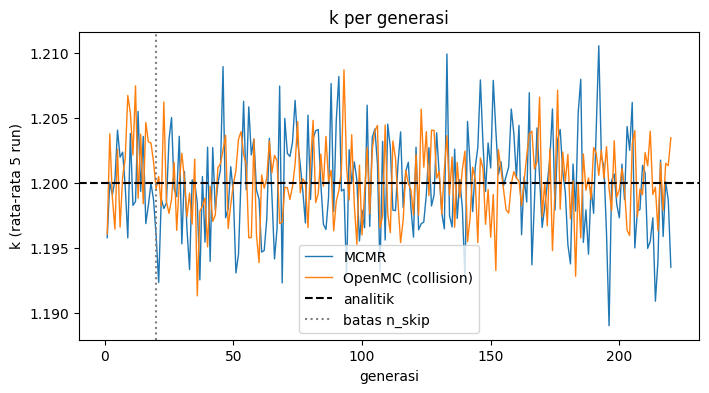

In [7]:
m = np.loadtxt(mcmr_csv, delimiter=",", skiprows=1)
o = np.loadtxt(omc_csv,  delimiter=",", skiprows=1)

def per_run_means(data, col):
    return np.array([data[(data[:, 0] == r) & (data[:, 2 if data is o else 1] > n_skip), col].mean()
                     for r in range(1, N_run + 1)])

mm = per_run_means(m, 2)
e_m = mm.std(ddof=1) / np.sqrt(N_run)
print(f"k analitik          = {k_analitik:.5f}")
print(f"MCMR                = {mm.mean():.5f} +- {e_m:.5f}  ({(mm.mean()-k_analitik)*1e5:+.0f} pcm)")
for name, col in (("collision", 3), ("tracklength", 4)):
    v = per_run_means(o, col); e = v.std(ddof=1) / np.sqrt(N_run)
    z = (mm.mean() - v.mean()) / np.hypot(e_m, e)
    print(f"OpenMC {name:11s} = {v.mean():.5f} +- {e:.5f}  ({(v.mean()-k_analitik)*1e5:+.0f} pcm)   z(MCMR-OpenMC) = {z:+.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
gens = np.arange(1, n_gen + 1)
ax.plot(gens, np.mean([m[m[:, 0] == r, 2] for r in range(1, N_run + 1)], axis=0), lw=1, label="MCMR")
ax.plot(gens, np.mean([o[o[:, 0] == r, 3] for r in range(1, N_run + 1)], axis=0), lw=1, label="OpenMC (collision)")
ax.axhline(k_analitik, color="k", ls="--", label="analitik")
ax.axvline(n_skip, color="gray", ls=":", label="batas n_skip")
ax.set_xlabel("generasi"); ax.set_ylabel(f"k (rata-rata {N_run} run)"); ax.legend(); ax.set_title("k per generasi")
plt.show()